Практикалық жұмыс 9 - Naive Bayes көмегімен мәтіндік құжаттарды жіктеу


Табиғи тілді өңдеу және машиналық оқыту салаларында [**Naive Bayes**](https://www.geeksforgeeks.org/machine-learning/naive-bayes-classifiers/) — мәтіндік құжаттарды жіктеуге арналған кең таралған әдіс.

Бұл әдіс **Байес теоремасын** пайдаланып, мәтінде белгілі бір сөздердің кездесу ықтималдығына қарай құжаттарды алдын ала анықталған кластарға бөледі.

Бұл мақалада Python тілінде **Naive Bayes алгоритмі арқылы мәтінді жіктеуді** жүзеге асырамыз.

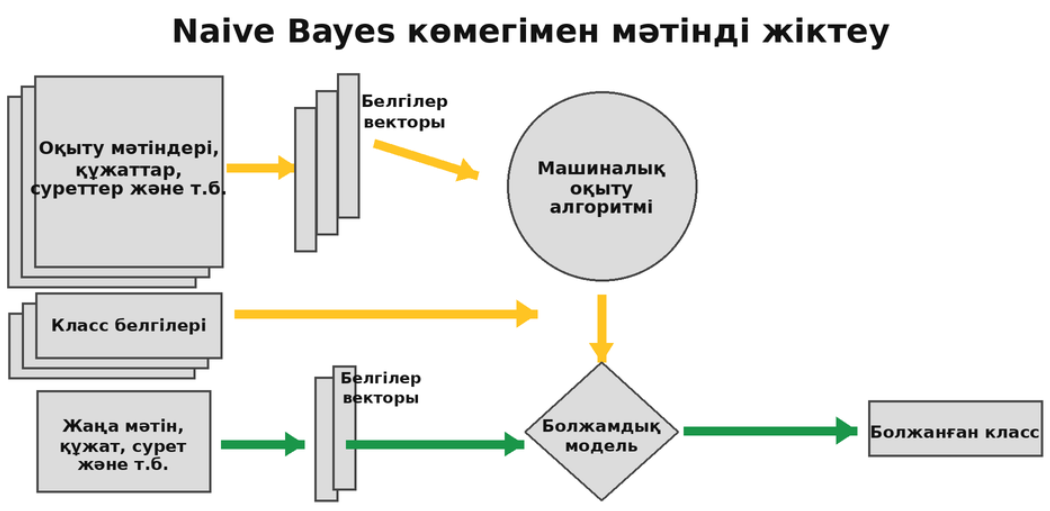

Қолданылатын деректер жиыны мәтіндік деректерден тұрады және төрт класқа бөлінеді:

- **Technology** — Технология;
- **Sports** — Спорт;
- **Politics** — Саясат;
- **Entertainment** — Ойын-сауық.

Әрбір жазба белгілі бір тақырыпқа қатысты қысқа сөйлемнен немесе мәтіннен тұрады. Ал класс белгісі мәтіннің қай санатқа жататынын көрсетеді.

### 1. Кітапханаларды импорттау

Қажетті кітапханаларды импорттаймыз: [**scikit-learn**](https://www.geeksforgeeks.org/machine-learning/learning-model-building-scikit-learn-python-machine-learning-library/), [**Pandas**](https://www.geeksforgeeks.org/pandas/pandas-tutorial/), [**Matplotlib**](https://www.geeksforgeeks.org/python/python-introduction-matplotlib/) және [**NumPy**](https://www.geeksforgeeks.org/python/introduction-to-numpy/).

- **`CountVectorizer`** — мәтіндегі сөздердің кездесу санын есептеп, мәтіндік деректерді сандық белгілерге айналдырады.
- **`MultinomialNB`** — мультиномиалды деректерге арналған Naive Bayes классификаторы. Ол мәтіндерді жіктеу үшін өте қолайлы.

Ағылшын нұсқасындағыдай қайта сызылған қазақша сурет:

[Naive_Bayes_matin_jikteu_qazaqsha.png](https://chatgpt.com/library?file_id=libfile_98b5dd07f2b481a49e3c22ff85f1a915&account_id=5fc06a67-1337-4950-9279-f03b0ffa9043)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.feature_extraction.text import CountVectorizer

### 2. Деректер жиынын **жүктеу**

Бұл қадамда деректер жиынын жүктейміз.

In [3]:
data = pd.read_csv('synthetic_text_data.csv')
X = data['text']
y = data['label']

### 3. Деректерді **бөлу**

Енді деректер жиынын оқыту және тестілік жиындарға бөлеміз. Оқыту жиыны модельді үйрету үшін, ал тестілік жиын оның жұмыс сапасын бағалау үшін қолданылады.

- `train_test_split` — деректердің 80%-ын оқытуға, ал 20%-ын тестілеуге бөледі.
- `random_state` — кодты қайта іске қосқанда деректердің бірдей бөлінуін қамтамасыз етеді.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### **4. Мәтінді алдын ала өңдеу: мәтінді сандық белгілерге айналдыру**

Мәтіндік деректерді модельге бермес бұрын оларды сандық форматқа айналдыру қажет. Мәтіндегі сөздердің кездесу санын көрсететін матрица құру үшін [**`CountVectorizer`**](https://www.geeksforgeeks.org/nlp/using-countvectorizer-to-extracting-features-from-text/) қолданылады.

- **`CountVectorizer()`** — бастапқы мәтінді сөздердің кездесу саны көрсетілген матрицаға айналдырады.
- **`fit_transform()`** — оқыту деректеріндегі сөздерді зерттеп, сөздік құрады және мәтінді сандық векторларға айналдырады.
- **`transform()`** — оқыту деректерінен құрылған дайын сөздікті тест деректеріне қолданады. Жаңа сөздік құрмайды.

In [5]:
vectorizer = CountVectorizer()
X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

### **5. Naive Bayes классификаторын оқыту**

Деректер қажетті форматқа айналдырылғаннан кейін, **Naive Bayes классификаторын** оқыту деректерімен үйретеміз. Бұл жерде [**Multinomial Naive Bayes**](https://www.geeksforgeeks.org/machine-learning/multinomial-naive-bayes/) алгоритмін қолданамыз.

> **Multinomial Naive Bayes** — белгілері дискретті мәндерден тұратын жіктеу есептеріне арналған Naive Bayes классификаторының бір түрі. Мысалы, мәтінді жіктеуде белгілер ретінде сөздердің кездесу саны немесе жиілігі қолданылады.

In [6]:
model = MultinomialNB()
model.fit(X_train_vectorized, y_train)

MultinomialNB()

### **6. Болжам жасау**

Модель оқытылғаннан кейін, `X_test_vectorized` тест деректерін пайдаланып, олардың класс белгілерін болжаймыз.

In [7]:
y_pred = model.predict(X_test_vectorized)

### **7. Модельді бағалау**

Болжам жасалғаннан кейін модельдің жұмыс нәтижесін бағалау қажет. Модельдің қаншалықты дұрыс жұмыс істейтінін анықтау үшін **дәлдік көрсеткішін (`accuracy`)** және **қателер матрицасын (`confusion matrix`)** есептейміз.

- **`accuracy_score()`** — модель болжаған класс белгілерін (`y_pred`) нақты класс белгілерімен (`y_test`) салыстырып, модельдің жалпы дәлдігін есептейді.
- **`confusion_matrix()`** — модельдің әр санатты қаншалықты дұрыс жіктегенін көрсететін қателер матрицасын құрады.

Accuracy: 88.23529411764706%


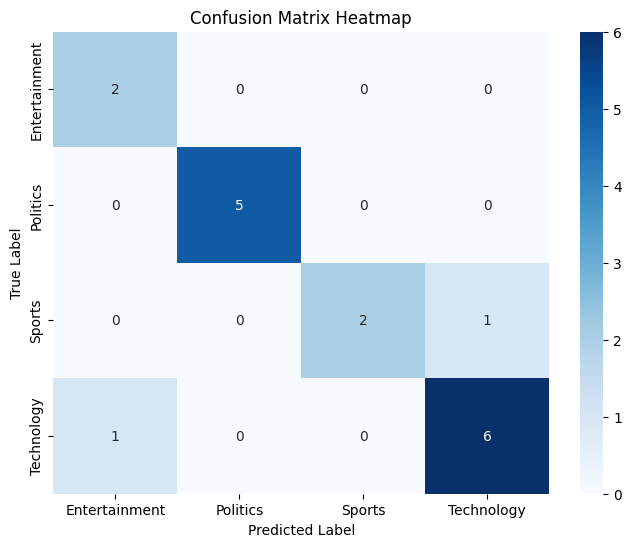

In [8]:
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)

print(f'Accuracy: {accuracy *100}%')

class_labels = np.unique(y_test)

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix Heatmap')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

Қателер матрицасының жылу картасына қарап, модельдің келесі санаттарды дұрыс болжағанын көруге болады:

- **Спорт — 2 мәтін;**
- **Технология — 5 мәтін;**
- **Саясат — 2 мәтін;**
- **Ойын-сауық — 6 мәтін.**

Жылу картасында дұрыс болжамдар қою түспен көрсетілген. Дегенмен модель кейбір мәтіндерді қате жіктеген.

### **8. Модель көрмеген жаңа деректерге болжам жасау**

In [9]:
user_input = ("I love artificial intelligence and machine learning")

user_input_vectorized = vectorizer.transform([user_input])
predicted_label = model.predict(user_input_vectorized)
print(f"The input text belongs to the '{predicted_label[0]}' category.")

The input text belongs to the 'Technology' category.
